Author:  
Manuel Eugenio Morocho Cayamcela, PhD

# **Assignment**  
## Outlier handling and group operations for e-commerce transactions

### **Objective and scope of the assignment:**

The objective of this assignment is to apply data mining techniques to identify the most relevant products in our dataset. In addition, the interquartile range (IQR) method will be used to detect and remove outliers, thereby improving the quality of our data and the accuracy of our analyses.

This assignment will cover the following aspects:

1. Loading and initial exploration of the data.
2. Exploratory data analysis to understand the characteristics and distributions of the variables.
3. Applying the IQR method to detect and remove outliers.
4. Applying data mining techniques to identify the most relevant products.
5. Interpreting and visualizing the results.

### **Phase I:** Data Loading and Preprocessing

#### Import the required libraries

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

%matplotlib inline

#### Data loading and preprocessing

In [ ]:
# Load the CSV (place the file in the same folder as this notebook)
transactions = pd.read_csv('ecommerce_transactions(in).csv')

# First five rows
transactions.head()

In [ ]:
# Data types and non-null counts
transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536350 entries, 0 to 536349
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionNo  536350 non-null  object 
 1   Date           535111 non-null  object 
 2   ProductNo      535111 non-null  object 
 3   ProductName    535111 non-null  object 
 4   Price          535111 non-null  float64
 5   Quantity       535111 non-null  float64
 6   CustomerNo     535056 non-null  float64
 7   Country        535111 non-null  object 
dtypes: float64(3), object(5)
memory usage: 32.7+ MB


### **Phase II:** Cleaning Outliers

In [ ]:
# Number of missing values per column
transactions.isnull().sum()

TransactionNo       0
Date             1239
ProductNo        1239
ProductName      1239
Price            1239
Quantity         1239
CustomerNo       1294
Country          1239
dtype: int64

In [ ]:
# Remove rows containing null values
rows_initial = len(transactions)
transactions = transactions.dropna().copy()
rows_after_nulls = len(transactions)
print(f'Original records: {rows_initial:,}')
print(f'Rows removed due to missing values: {rows_initial - rows_after_nulls:,}')
print(f'Records after dropna(): {rows_after_nulls:,}')

Original records: 536,350
Rows removed due to missing values: 1,294
Records after dropna(): 535,056


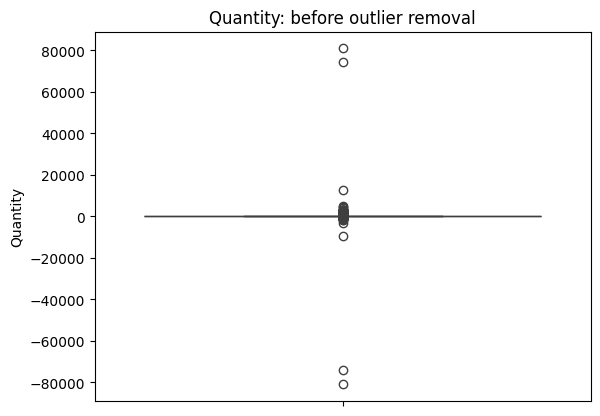

In [ ]:
# Distribution of product quantities before outlier removal
sns.boxplot(y=transactions['Quantity'])
plt.title('Quantity: before outlier removal')
plt.show()

In [ ]:
# Quartiles and interquartile range (IQR)
Q1 = transactions['Quantity'].quantile(0.25)
Q3 = transactions['Quantity'].quantile(0.75)
IQR = Q3 - Q1
print(f'Q1 = {Q1:g}, Q3 = {Q3:g}, IQR = {IQR:g}')
IQR

Q1 = 1, Q3 = 10, IQR = 9


np.float64(9.0)

In [ ]:
# IQR rule with factor 1.5
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Exclude Quantity values outside the IQR bounds
outliers = (transactions['Quantity'] < lower_bound) | (transactions['Quantity'] > upper_bound)
outlier_count = int(outliers.sum())
transactions = transactions.loc[~outliers].copy()
print(f'IQR limits: [{lower_bound:g}, {upper_bound:g}]')
print(f'Rows removed as outliers: {outlier_count:,}')
print(f'Rows retained after IQR filtering: {len(transactions):,}')

IQR limits: [-12.5, 23.5]
Rows removed as outliers: 57,212
Rows retained after IQR filtering: 477,844


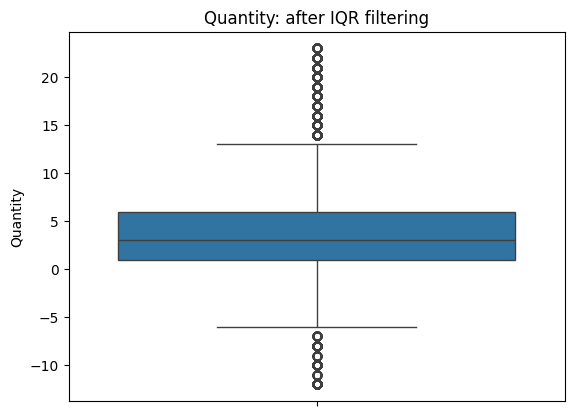

In [ ]:
# Boxplot after applying the IQR rule
sns.boxplot(y=transactions['Quantity'])
plt.title('Quantity: after IQR filtering')
plt.show()

Non-positive quantity rows removed: 7,515
Final records: 470,329


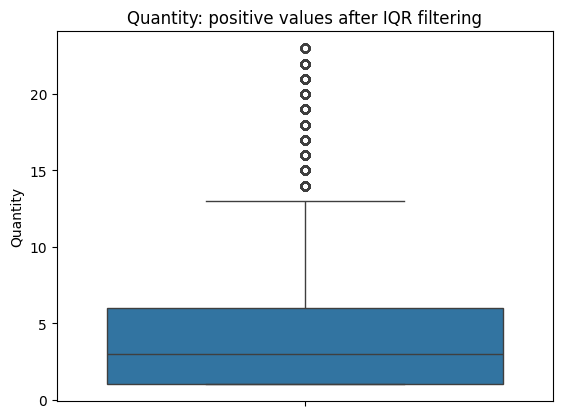

In [ ]:
# Filter out returns/cancellations represented by non-positive Quantity
nonpositive_count = int((transactions['Quantity'] <= 0).sum())
transactions = transactions.loc[transactions['Quantity'] > 0].copy()
print(f'Non-positive quantity rows removed: {nonpositive_count:,}')
print(f'Final records: {len(transactions):,}')

# Final distribution of positive Quantity
sns.boxplot(y=transactions['Quantity'])
plt.title('Quantity: positive values after IQR filtering')
plt.show()

### **Phase III:** Best-selling and highest-revenue products

Create a new column for the revenue per sale

In [ ]:
# Revenue of each transaction line
transactions['Revenue'] = transactions['Price'] * transactions['Quantity']
transactions.head()

,TransactionNo,Date,ProductNo,ProductName,Price,Quantity,CustomerNo,Country,Revenue
0,581482,12/9/2019,22485,Set Of 2 Wooden Market Crates,21.47,12.0,17490.0,United Kingdom,257.64
2,581475,12/9/2019,23235,Storage Tin Vintage Leaf,11.53,12.0,13069.0,United Kingdom,138.36
3,581475,12/9/2019,23272,Tree T-Light Holder Willie Winkie,10.65,12.0,13069.0,United Kingdom,127.80
4,581475,12/9/2019,23239,Set Of 4 Knick Knack Tins Poppies,11.94,6.0,13069.0,United Kingdom,71.64
6,581475,12/9/2019,22118,Joy Wooden Block Letters,11.53,18.0,13069.0,United Kingdom,207.54


Review the 10 best-selling products

In [ ]:
# Sum quantities per product and rank from highest to lowest
grouped_products = transactions.groupby('ProductName')
total_quantity_by_product = grouped_products['Quantity'].sum()
best_selling_products = total_quantity_by_product.sort_values(ascending=False)
best_selling_products.head(10)

ProductName
Jumbo Bag Red Retrospot               14050.0
Assorted Colour Bird Ornament         11062.0
Cream Hanging Heart T-Light Holder    10960.0
Lunch Bag Red Retrospot               10541.0
Jumbo Bag Vintage Doily                9306.0
Lunch Bag Vintage Doily                8405.0
Regency Cakestand 3 Tier               8328.0
Lunch Bag Suki Design                  8268.0
Lunch Bag Black Skull                  8218.0
Lunch Bag Cars Blue                    7928.0
Name: Quantity, dtype: float64

Visualize the 10 best-selling products

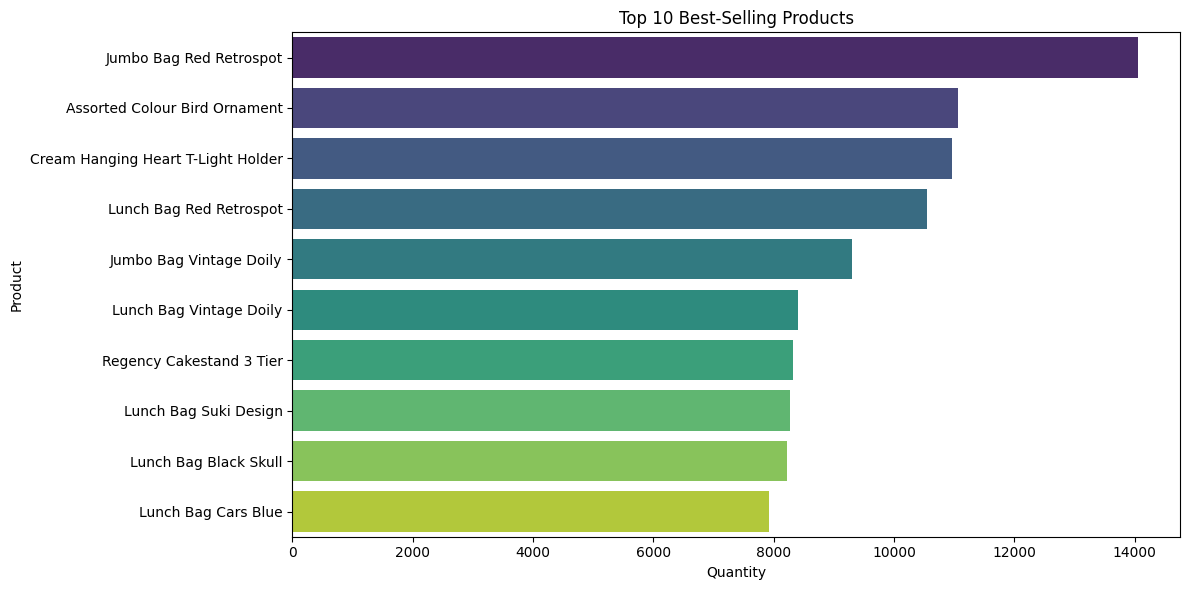

In [ ]:
# Bar chart: highest quantities sold
plt.figure(figsize=(12, 6))
top10_quantity = best_selling_products.head(10)
sns.barplot(x=top10_quantity, y=top10_quantity.index,
            hue=top10_quantity.index, palette='viridis', legend=False)
plt.title('Top 10 Best-Selling Products')
plt.xlabel('Quantity')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

Review the 10 products that have generated the most revenue

In [ ]:
# Sum revenue per product and rank in descending order
grouped_products = transactions.groupby('ProductName')
total_revenue_by_product = grouped_products['Revenue'].sum()
top_revenue_products = total_revenue_by_product.sort_values(ascending=False)
top_revenue_products.head(10)

ProductName
Regency Cakestand 3 Tier              188831.32
Cream Hanging Heart T-Light Holder    143410.29
Assorted Colour Bird Ornament         129096.00
Party Bunting                         122645.19
Jumbo Bag Red Retrospot                88625.81
Jam Making Set Printed                 88106.25
Jumbo Shopper Vintage Red Paisley      87483.07
Jumbo Storage Bag Suki                 87134.08
Popcorn Holder                         85207.51
Natural Slate Heart Chalkboard         81275.77
Name: Revenue, dtype: float64

Visualize the products that have generated the most revenue

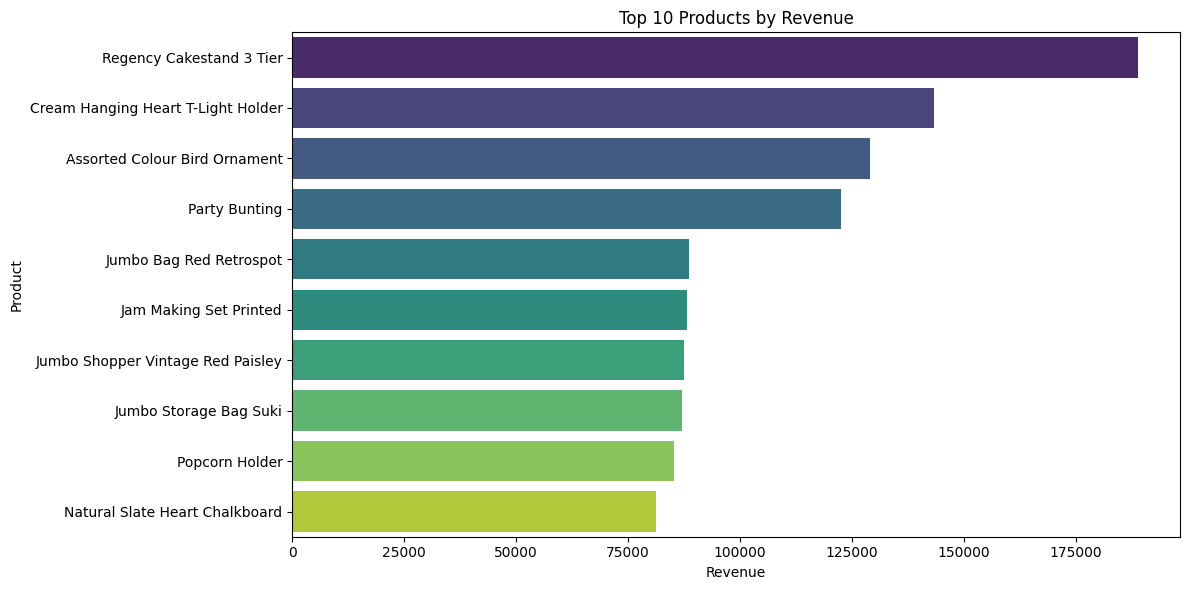

In [ ]:
# Bar chart: products generating the greatest revenue
plt.figure(figsize=(12, 6))
top10_revenue = top_revenue_products.head(10)
sns.barplot(x=top10_revenue, y=top10_revenue.index,
            hue=top10_revenue.index, palette='viridis', legend=False)
plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

Visualize the distribution of revenue by month

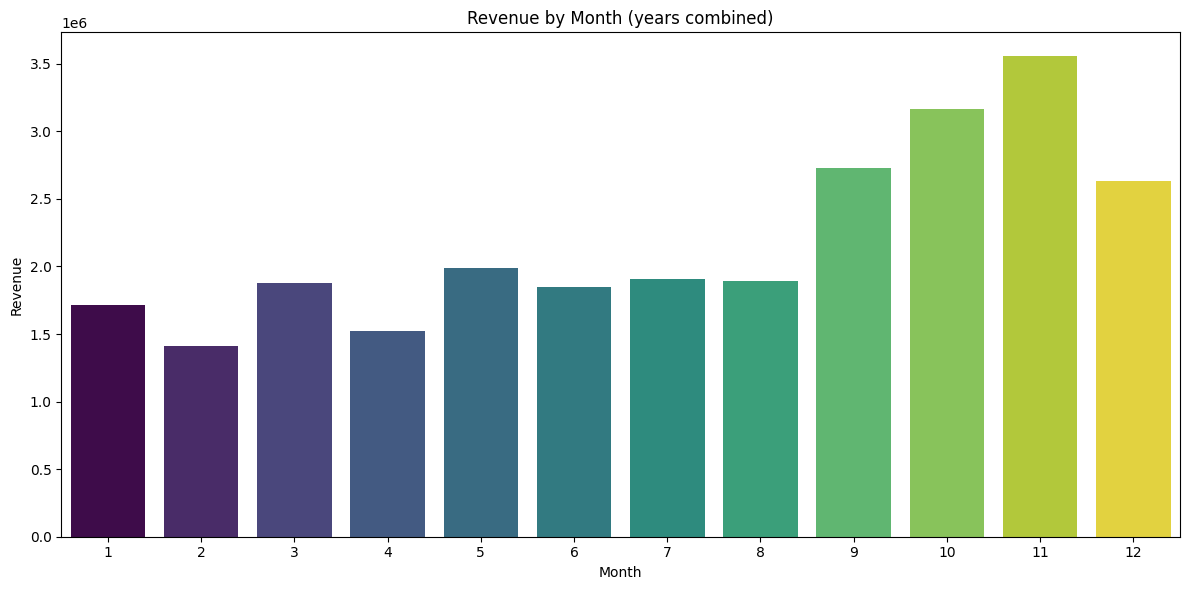

In [ ]:
# Convert dates to datetime using the specified month/day/year format
transactions['Date'] = pd.to_datetime(transactions['Date'], format='%m/%d/%Y')

# Extract the month and aggregate revenue across all observed years
transactions['Month'] = transactions['Date'].dt.month
sales_by_month = transactions.groupby('Month')['Revenue'].sum()

plt.figure(figsize=(12, 6))
sns.barplot(x=sales_by_month.index, y=sales_by_month.values,
            hue=sales_by_month.index, palette='viridis', legend=False)
plt.title('Revenue by Month (years combined)')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()

Visualize the distribution of sales by day of the week with a bar chart

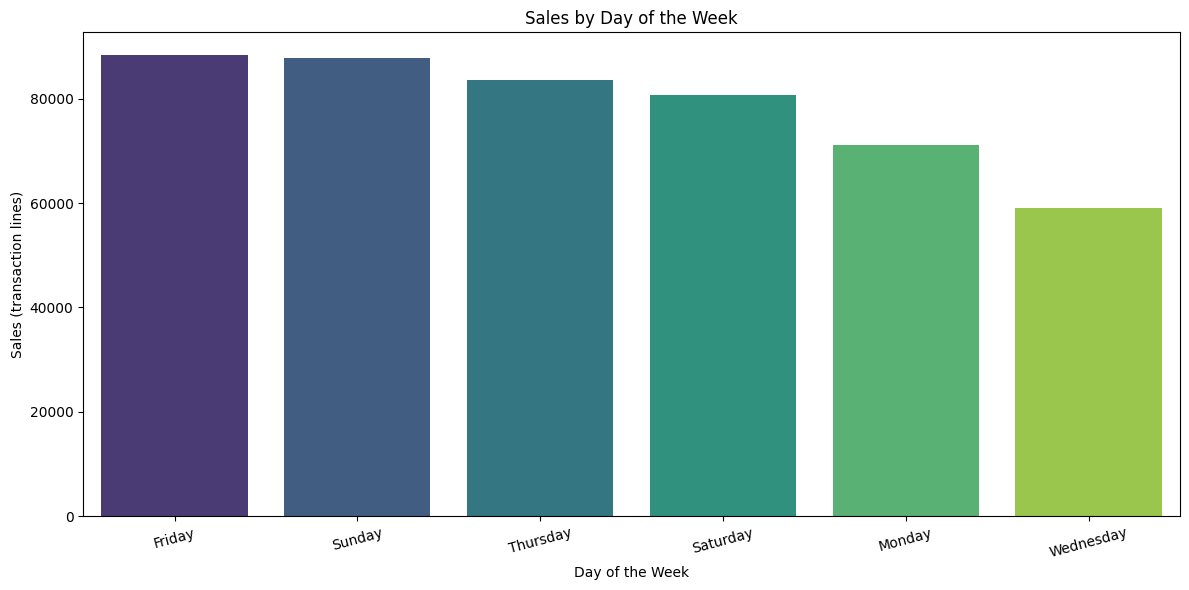

In [ ]:
# Count transaction lines per weekday
transactions['DayOfWeek'] = transactions['Date'].dt.day_name()
sales_by_weekday = transactions['DayOfWeek'].value_counts()

plt.figure(figsize=(12, 6))
sns.barplot(x=sales_by_weekday.index, y=sales_by_weekday.values,
            hue=sales_by_weekday.index, palette='viridis', legend=False)
plt.title('Sales by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Sales (transaction lines)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Results and interpretation

- **Data cleaning.** Missing observations were removed using `dropna()`. The 1.5×IQR rule was applied to the `Quantity` column, followed by exclusion of non-positive quantities (returns/cancellations). The aim is to analyze regular positive-quantity purchases, not to estimate the financial impact of returns.
- **Best-selling vs. highest-revenue products.** The former ranks total **units** sold; the latter ranks total **Revenue = Price × Quantity**. The rankings are not interchangeable.
- **Monthly revenue.** The `Month` aggregation merges the same calendar month across all years present in the dataset. In this file, December occurs in both **2018 and 2019**; this chart is therefore not a chronological year-on-year trend.
- **Weekday counts.** The provided `value_counts()` task counts **transaction lines**, not distinct `TransactionNo` invoices. Thus, it describes row frequency rather than unique customer orders.
- **Limitation.** Removing high-quantity transactions with the IQR method can exclude legitimate bulk purchases. The reported product rankings and total revenues refer only to the filtered dataset.

- **Temporal coverage.** The observations cover **December 1, 2018 through December 9, 2019**. December 2019 is partial, and the monthly bar chart combines December 2018 with December 2019, as requested in the assignment. Therefore, month-level bars should not be read as directly comparable full-month observations.
- **Potential duplicates.** An independent audit found **5,053 exactly duplicated rows** in the filtered dataset, considering all eight original CSV fields. These have **not** been removed: the professor's instructions do not request deduplication, and identical invoice lines may need business-context verification before altering sales totals.
- **Unit of analysis.** Each row is an invoice line, so weekday counts are **line-item counts** rather than a count of distinct orders. This follows the requested `value_counts()` calculation.
